# Employee Performance Prediction – HR Analytics

**Goal:** identify the main drivers of employee performance (0–100 score) at a mid-sized Australian manufacturer, and predict performance from demographic, job and engagement variables.

**Data:** cleaned HR dataset – 1,201 employees, 30 variables (1,230 raw records before cleaning).

**Approach:** Linear Regression baseline → Gradient Boosting improved model, evaluated on a 70/30 train/test split and 5-fold cross-validation.

## 1. Setup

In [62]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

os.makedirs("images", exist_ok=True)

## 2. Load data
In Colab, upload `Step4_Cleaned_Final_NoMissing.xlsx` using the folder icon on the left before running.

In [63]:
df = pd.read_excel("Step4_Cleaned_Final_NoMissing.xlsx")
print("Loaded:", df.shape)
df.head()

Loaded: (1201, 30)


,Employee_ID,Age,Department,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,JobInvolvement,JobLevel,JobRotation,...,TotalWorkingYears,Training,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Performance,TenureRatio,ManagerTenureDiff
0,64,25,Production,2,3,1,Male,3,1,1.0,...,6,N,3,2,2.0,0.0,2.0,47,1.000000,0.0
1,339,32,Research & Development,7,4,2,Female,4,1,2.0,...,6,Y,3,3,2.0,0.0,2.0,61,0.666667,1.0
2,376,33,Research & Development,9,3,4,Male,2,3,2.0,...,9,Y,3,3,2.0,1.0,2.0,62,0.666667,1.0
3,429,36,Sales,18,2,2,Male,2,3,3.5,...,10,Y,3,10,9.0,7.5,0.0,82,0.900000,10.0
4,441,32,Research & Development,17,3,4,Male,3,2,3.5,...,10,Y,2,9,5.0,1.0,6.0,67,0.555556,3.0


## 3. Prepare features
`Employee_ID` is an identifier, not a driver of performance, so it is removed. Categorical variables are one-hot encoded.

In [64]:
df["Department"] = df["Department"].replace({"Fin": "Finance"})

target = "Performance"
X = df.drop(columns=[target, "Employee_ID"])
y = df[target]

X = pd.get_dummies(X, drop_first=True)
print("Features after encoding:", X.shape[1])

Features after encoding: 43


In [65]:
for col in df.select_dtypes(include="object").columns:
    print(col, sorted(df[col].unique()))

Department ['Finance', 'Human Resources', 'IT_Support', 'Production', 'Research & Development', 'Sales']
Gender ['Female', 'Male']
FeedbackFromManager ['H', 'L']
Mentoring ['N', 'Y']
Autonomy ['N', 'Y']
JobRole ['Accountant', 'Customercare Representative', 'Human Resources', 'IT specialists', 'Machinists', 'Manager', 'Manufacturing Director', 'Production Supervisors', 'Research Director', 'Research and Design Specialists', 'Sales Executive', 'Sales Manager', 'Sales Representative']
OverTime ['No', 'Yes']
Tools ['H', 'L']
Training ['N', 'Y']


## 4. Train/test split (70/30)

In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (840, 43) | Test: (361, 43)


## 5. Baseline model – Linear Regression


In [67]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_s, y_train)
y_pred_lr = lr.predict(X_test_s)

r2_lr   = r2_score(y_test, y_pred_lr)
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
print(f"Linear Regression  R²={r2_lr:.3f} | MAE={mae_lr:.3f} | RMSE={rmse_lr:.3f}")

Linear Regression  R²=0.528 | MAE=8.191 | RMSE=10.782


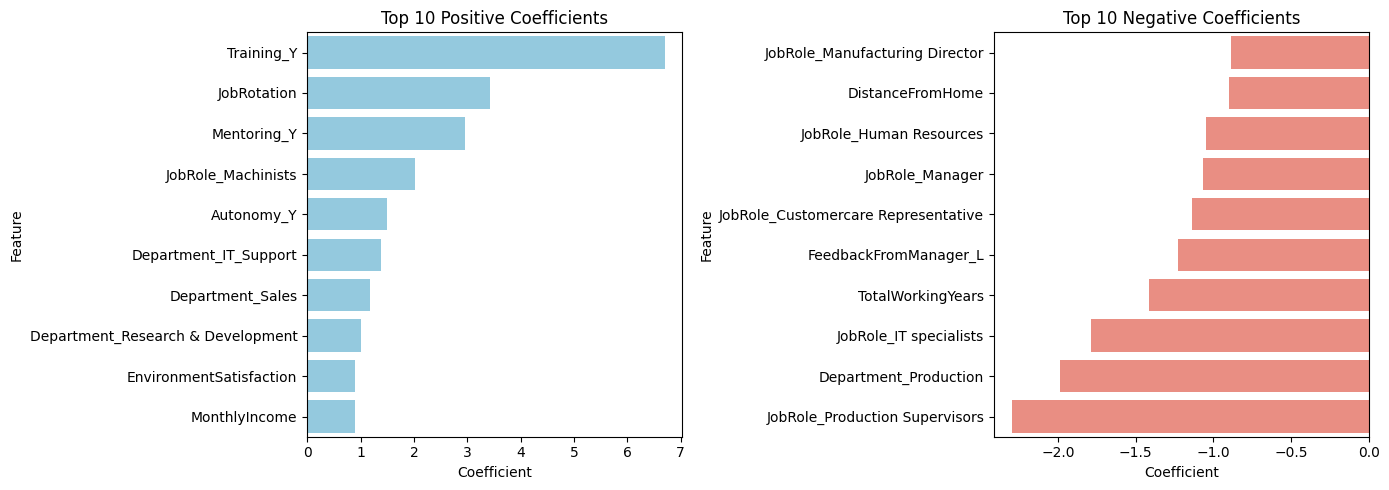

In [68]:
coef_df = pd.DataFrame({"Feature": X.columns, "Coefficient": lr.coef_}).sort_values("Coefficient", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=coef_df.head(10), x="Coefficient", y="Feature", color="skyblue", ax=axes[0])
axes[0].set_title("Top 10 Positive Coefficients")
sns.barplot(data=coef_df.tail(10), x="Coefficient", y="Feature", color="salmon", ax=axes[1])
axes[1].set_title("Top 10 Negative Coefficients")
plt.tight_layout()
plt.savefig("images/lr_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

### Residual checks (Linear Regression)

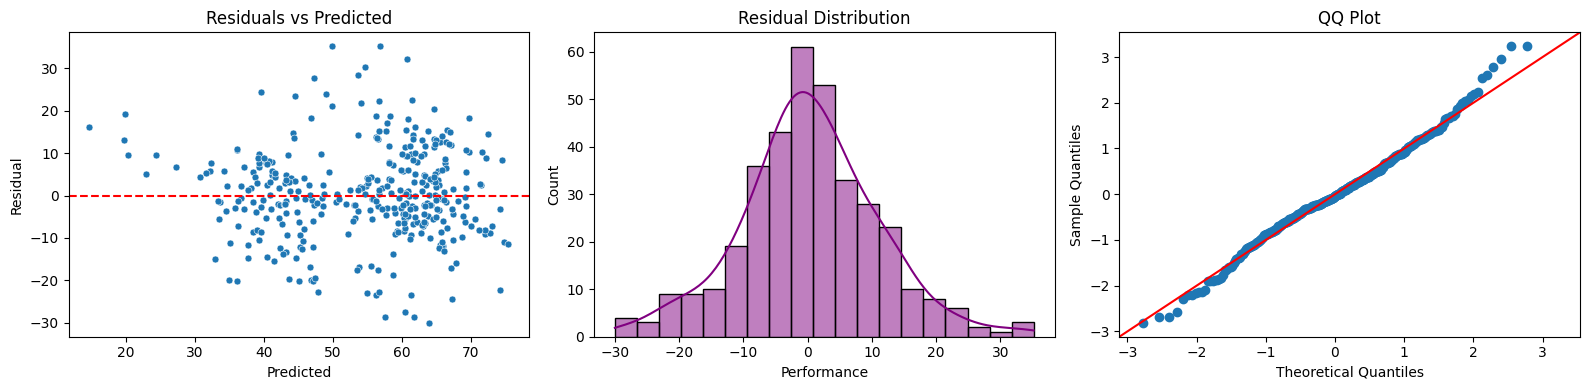

In [69]:
residuals_lr = y_test - y_pred_lr

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(x=y_pred_lr, y=residuals_lr, s=25, ax=axes[0])
axes[0].axhline(0, color="red", ls="--")
axes[0].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs Predicted")
sns.histplot(residuals_lr, kde=True, color="purple", ax=axes[1])
axes[1].set_title("Residual Distribution")
sm.qqplot(residuals_lr, line="45", fit=True, ax=axes[2])
axes[2].set_title("QQ Plot")
plt.tight_layout()
plt.savefig("images/lr_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Improved model – Gradient Boosting
Captures non-linear effects and interactions the linear model misses.

In [70]:
gb = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.1, max_depth=4, random_state=42
)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

r2_gb   = r2_score(y_test, y_pred_gb)
mae_gb  = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
print(f"Gradient Boosting  R²={r2_gb:.3f} | MAE={mae_gb:.3f} | RMSE={rmse_gb:.3f}")

Gradient Boosting  R²=0.632 | MAE=7.230 | RMSE=9.518


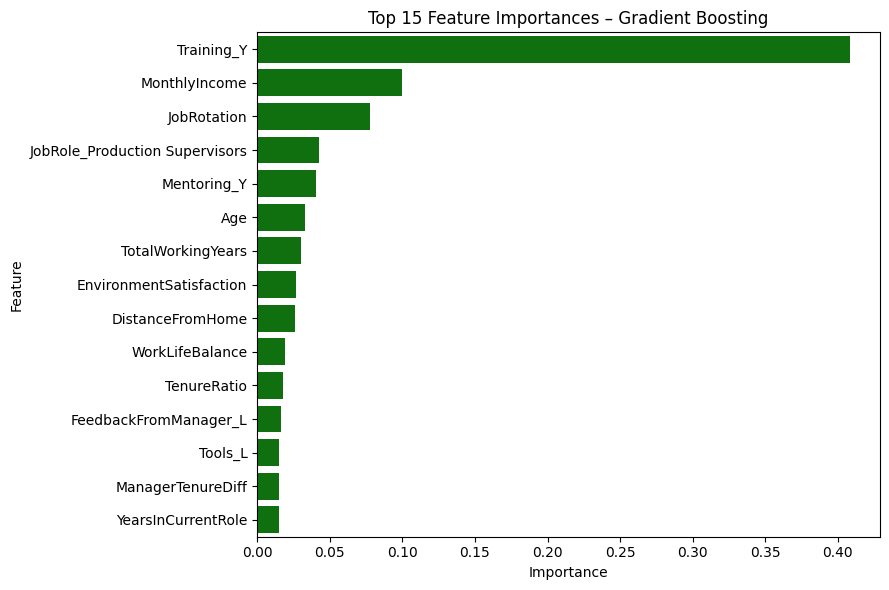

,Feature,Importance
42,Training_Y,0.408575
7,MonthlyIncome,0.099457
6,JobRotation,0.077504
34,JobRole_Production Supervisors,0.042375
26,Mentoring_Y,0.040810
0,Age,0.033024
11,TotalWorkingYears,0.030104
3,EnvironmentSatisfaction,0.026571
1,DistanceFromHome,0.025726
12,WorkLifeBalance,0.019254


In [71]:
fi = pd.DataFrame({"Feature": X.columns, "Importance": gb.feature_importances_}).sort_values("Importance", ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=fi.head(15), x="Importance", y="Feature", color="green")
plt.title("Top 15 Feature Importances – Gradient Boosting")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

fi.head(10)

## 7. Cross-validation (5-fold)
Checks that results hold across different splits of the data, not just one lucky split.

In [72]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_lr = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X, y, cv=kf, scoring="r2")
cv_gb = cross_val_score(
    GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=4, random_state=42),
    X, y, cv=kf, scoring="r2"
)

print(f"5-fold CV R² – Linear Regression: {cv_lr.mean():.3f} ± {cv_lr.std():.3f}")
print(f"5-fold CV R² – Gradient Boosting: {cv_gb.mean():.3f} ± {cv_gb.std():.3f}")

5-fold CV R² – Linear Regression: 0.524 ± 0.056
5-fold CV R² – Gradient Boosting: 0.634 ± 0.036


## 8. Model comparison

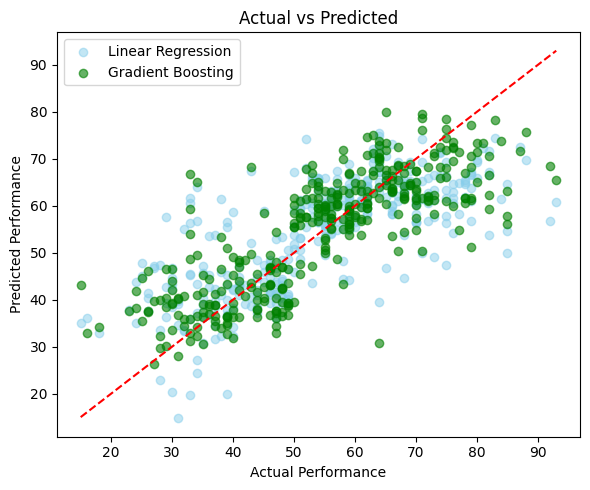

In [73]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_lr, alpha=0.5, label="Linear Regression", color="skyblue")
plt.scatter(y_test, y_pred_gb, alpha=0.6, label="Gradient Boosting", color="green")
mn, mx = y_test.min(), y_test.max()
plt.plot([mn, mx], [mn, mx], "r--")
plt.xlabel("Actual Performance"); plt.ylabel("Predicted Performance")
plt.title("Actual vs Predicted")
plt.legend(); plt.tight_layout()
plt.savefig("images/actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

                       Model  Test R²   MAE   RMSE  5-fold CV R²
Linear Regression (Baseline)    0.528 8.191 10.782         0.524
Gradient Boosting (Improved)    0.632 7.230  9.518         0.634

Metric  Improvement (%)
    R²             19.7
   MAE             11.7
  RMSE             11.7


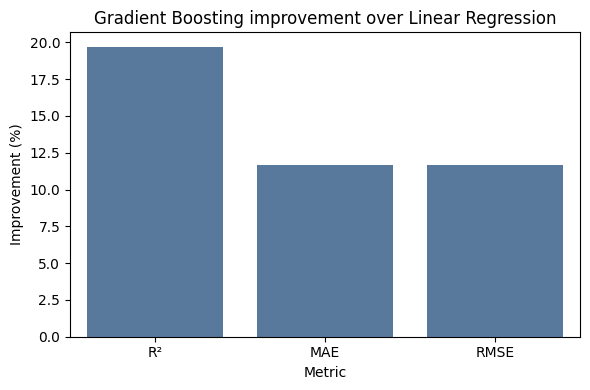

In [74]:
results = pd.DataFrame({
    "Model": ["Linear Regression (Baseline)", "Gradient Boosting (Improved)"],
    "Test R²": [r2_lr, r2_gb],
    "MAE": [mae_lr, mae_gb],
    "RMSE": [rmse_lr, rmse_gb],
    "5-fold CV R²": [cv_lr.mean(), cv_gb.mean()],
}).round(3)
print(results.to_string(index=False))

improv = pd.DataFrame({
    "Metric": ["R²", "MAE", "RMSE"],
    "Improvement (%)": [
        (r2_gb - r2_lr) / r2_lr * 100,
        (mae_lr - mae_gb) / mae_lr * 100,
        (rmse_lr - rmse_gb) / rmse_lr * 100,
    ],
}).round(1)
print()
print(improv.to_string(index=False))

plt.figure(figsize=(6, 4))
sns.barplot(data=improv, x="Metric", y="Improvement (%)", color="#4e79a7")
plt.title("Gradient Boosting improvement over Linear Regression")
plt.tight_layout()
plt.savefig("images/improvement.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Key insights

- **Training** is the strongest predictor of performance, accounting for about 41% of the Gradient Boosting model's importance. Employees who received training consistently scored higher.
- **Job rotation and mentoring** are the next most important factors. Both models show a positive link with performance.
- **Monthly income** ranks second in the Gradient Boosting model but has little effect in the linear model. This suggests its relationship with performance is non-linear, which helps explain why Gradient Boosting performs better.
- **Low manager feedback** and **Production roles** are associated with lower performance.
- **Overtime and work-life balance** have only a minor effect in this dataset.

**Model performance:** Gradient Boosting explains about 63% of the variation in performance (test R² = 0.632, 5-fold CV R² = 0.634), compared with 53% for Linear Regression. On average, its predictions are within about 7 points on a 0–100 scale.

**Limitations:** The data comes from a single company, so results may not apply to other organisations. The model identifies associations, not causes. Model settings were not tuned, so further improvement is possible.